# Рынок заведений общественного питания Москвы

**Описание проекта**
Инвесторы из фонда «Shut Up and Take My Money» решили попробовать себя в новой области и открыть заведение общественного питания в Москве. Заказчики ещё не знают, что это будет за место: кафе, ресторан, пиццерия, паб или бар, — и какими будут расположение, меню и цены.

**Цель проекта** - подготовить исследование рынка Москвы, найти интересные особенности и презентовать полученные результаты, которые в будущем помогут в выборе подходящего инвесторам места.

**Описание данных**

Датасет с заведениями общественного питания Москвы, составленный на основе данных сервисов Яндекс Карты и Яндекс Бизнес на лето 2022 года.

- `name` — название заведения;
- `address` — адрес заведения;
- `category` — категория заведения, например «кафе», «пиццерия» или «кофейня»;
- `hours` — информация о днях и часах работы;
- `lat` — широта географической точки, в которой находится заведение;
- `lng` — долгота географической точки, в которой находится заведение;
- `rating` — рейтинг заведения по оценкам пользователей в Яндекс Картах;
- `price` — категория цен в заведении;
- `avg_bill` — строка, которая хранит среднюю стоимость заказа в виде диапазона;
- `middle_avg_bill` — число с оценкой среднего чека;
- `middle_coffee_cup` — число с оценкой одной чашки капучино;
- `chain` — число, которое показывает, является ли заведение сетевым;
- `district` — административный район, в котором находится заведение;
- `seats` — количество посадочных мест.

**План работы**

- Шаг 1. Загрузить данные и изучить общую информацию
- Шаг 2. Выполнить предобработку данных
- Шаг 3. Анализ данных
- Шаг 4. Детализация исследования: открытие кофейни
- Шаг 5. Подготовка презентации

## Шаг 1. Загрузка данных и изучение общей информации

In [1]:
import pandas as pd

import numpy as np
import seaborn as sns
from matplotlib import pyplot as plt
from plotly import graph_objects as go
import plotly.express as px 

In [2]:
!pip install folium

In [3]:
import folium
from folium import Map, Marker
from folium.plugins import MarkerCluster
from folium import Map, Choropleth
import json

In [4]:
try:
    df = pd.read_csv('/datasets/moscow_places.csv')
except:
    df = pd.read_csv('moscow_places.csv')
    
df.head()

,name,category,address,district,hours,lat,lng,rating,price,avg_bill,middle_avg_bill,middle_coffee_cup,chain,seats
0,WoWфли,кафе,"Москва, улица Дыбенко, 7/1",Северный административный округ,"ежедневно, 10:00–22:00",55.878494,37.478860,5.0,NaN,NaN,NaN,NaN,0,NaN
1,Четыре комнаты,ресторан,"Москва, улица Дыбенко, 36, корп. 1",Северный административный округ,"ежедневно, 10:00–22:00",55.875801,37.484479,4.5,выше среднего,Средний счёт:1500–1600 ₽,1550.0,NaN,0,4.0
2,Хазри,кафе,"Москва, Клязьминская улица, 15",Северный административный округ,"пн-чт 11:00–02:00; пт,сб 11:00–05:00; вс 11:00...",55.889146,37.525901,4.6,средние,Средний счёт:от 1000 ₽,1000.0,NaN,0,45.0
3,Dormouse Coffee Shop,кофейня,"Москва, улица Маршала Федоренко, 12",Северный административный округ,"ежедневно, 09:00–22:00",55.881608,37.488860,5.0,NaN,Цена чашки капучино:155–185 ₽,NaN,170.0,0,NaN
4,Иль Марко,пиццерия,"Москва, Правобережная улица, 1Б",Северный административный округ,"ежедневно, 10:00–22:00",55.881166,37.449357,5.0,средние,Средний счёт:400–600 ₽,500.0,NaN,1,148.0


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8406 entries, 0 to 8405
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   name               8406 non-null   object 
 1   category           8406 non-null   object 
 2   address            8406 non-null   object 
 3   district           8406 non-null   object 
 4   hours              7870 non-null   object 
 5   lat                8406 non-null   float64
 6   lng                8406 non-null   float64
 7   rating             8406 non-null   float64
 8   price              3315 non-null   object 
 9   avg_bill           3816 non-null   object 
 10  middle_avg_bill    3149 non-null   float64
 11  middle_coffee_cup  535 non-null    float64
 12  chain              8406 non-null   int64  
 13  seats              4795 non-null   float64
dtypes: float64(6), int64(1), object(7)
memory usage: 919.5+ KB


**Вывод**

Загружен датасет, кол-во заведений 8406. Во всех заведениях известно наименование, категория, метоположение, рейтинг и является ли заведение сетевым. Но не все заведения указывают часы работы, цены и количество мест. Данные содержат 3 типа: object, int64, float64

## Шаг 2. Предобработка данных

In [6]:
# смотрим, есть ли дубликаты в данных
df.duplicated().sum()

0

In [7]:
# смотрим кол-во пропусков
df.isna().sum()

name                    0
category                0
address                 0
district                0
hours                 536
lat                     0
lng                     0
rating                  0
price                5091
avg_bill             4590
middle_avg_bill      5257
middle_coffee_cup    7871
chain                   0
seats                3611
dtype: int64

Явных дубликатов не выявлено, но присутствуют пропуски. Посмотрим более детально на столбцы и проверим данные на неявные дубликаты

### 1.1 Столбец `name`

In [8]:
 df['name'].describe()

count     8406
unique    5614
top       Кафе
freq       189
Name: name, dtype: object

In [9]:
df['name'].value_counts()

Кафе                189
Шоколадница         120
Домино'с Пицца       76
Додо Пицца           74
One Price Coffee     71
                   ... 
Сащя                  1
Мой дом               1
Stardogs              1
Bar Park 15           1
Kebab Time            1
Name: name, Length: 5614, dtype: int64

Возможно здесь будут повторяющиеся имена, которые написаны по-разному. Строк много, поэтому ограничемся сведением всех названий к нижнему регистру, а остальное оставляем как есть

In [10]:
df['name'].str.lower().value_counts()

кафе                189
шоколадница         120
домино'с пицца       77
додо пицца           74
one price coffee     72
                   ... 
ах... плов            1
прошу к столу         1
кофе-порт             1
сметана               1
kebab time            1
Name: name, Length: 5512, dtype: int64

Кол-во точек стало меньше на 102

### 1.2 Столбец `category`

In [11]:
df['category'].value_counts() 

кафе               2378
ресторан           2043
кофейня            1413
бар,паб             765
пиццерия            633
быстрое питание     603
столовая            315
булочная            256
Name: category, dtype: int64

### 1.3 Столбец `address`

In [12]:
df['address'].value_counts()

Москва, проспект Вернадского, 86В                                                                      28
Москва, Усачёва улица, 26                                                                              26
Москва, площадь Киевского Вокзала, 2                                                                   20
Москва, Ярцевская улица, 19                                                                            20
Москва, Каширское шоссе, 61Г                                                                           16
                                                                                                       ..
Москва, улица Герасима Курина, 6                                                                        1
Москва, Кутузовский проспект, 36, стр. 5                                                                1
Москва, улица Мнёвники, 11                                                                              1
Москва, Западный административный округ, район

In [13]:
df['address'].str.lower().value_counts()

москва, проспект вернадского, 86в           28
москва, усачёва улица, 26                   26
москва, площадь киевского вокзала, 2        20
москва, ярцевская улица, 19                 20
москва, пресненская набережная, 2           16
                                            ..
москва, ярославское шоссе, 19, стр. 1        1
москва, улица арбат, 29                      1
москва, улица арбат, 21, стр. 1              1
москва, малахитовая улица, 3                 1
москва, чонгарский бульвар, 26а, корп. 1     1
Name: address, Length: 5752, dtype: int64

По адресу "Москва, проспект Вернадского, 86В" находится 28 заведений общепита. По этому адресу раположен Паrk фудхолл, поэтому такое кол-во заведений обосновано. Будем считать, что и по остальных адресам, где много заведений, тоже находятся подобные большие здания

При приведении названий к нижнему регистру кол-во строк уменьшилось на одну

### 1.4 Столбец `district`

In [14]:
df['district'].value_counts()

Центральный административный округ         2242
Северный административный округ             900
Южный административный округ                892
Северо-Восточный административный округ     891
Западный административный округ             851
Восточный административный округ            798
Юго-Восточный административный округ        714
Юго-Западный административный округ         709
Северо-Западный административный округ      409
Name: district, dtype: int64

### 1.5 Столбец `hours` 

In [15]:
df['hours'].value_counts()

ежедневно, 10:00–22:00                                                  759
ежедневно, круглосуточно                                                730
ежедневно, 11:00–23:00                                                  396
ежедневно, 10:00–23:00                                                  310
ежедневно, 12:00–00:00                                                  254
                                                                       ... 
пн-пт 17:00–03:00; сб,вс 17:00–05:00                                      1
пн,вт 09:00–21:00; ср-пт 09:00–22:00; сб 10:00–22:00; вс 10:00–21:00      1
пн-пт 12:00–01:00                                                         1
пн-пт 10:30–21:30; сб,вс 10:30–22:30                                      1
пн-сб 10:30–21:30                                                         1
Name: hours, Length: 1307, dtype: int64

In [16]:
# смотрим пропуски
df[df['hours'].isna()].head()

,name,category,address,district,hours,lat,lng,rating,price,avg_bill,middle_avg_bill,middle_coffee_cup,chain,seats
38,Ижора,булочная,"Москва, Ижорский проезд, 5А",Северный административный округ,NaN,55.888366,37.514856,4.4,NaN,NaN,NaN,NaN,0,NaN
40,Кафе,кафе,"Москва, Ижорская улица, 18, стр. 1",Северный административный округ,NaN,55.895115,37.524902,3.7,NaN,NaN,NaN,NaN,0,NaN
44,Кафетерий,кафе,"Москва, Ангарская улица, 24А",Северный административный округ,NaN,55.876289,37.519315,3.8,NaN,NaN,NaN,NaN,1,8.0
56,Рыба из тандыра,быстрое питание,"Москва, Коровинское шоссе, 46, стр. 5",Северный административный округ,NaN,55.888010,37.515960,1.5,NaN,NaN,NaN,NaN,0,NaN
108,Кафе,"бар,паб","Москва, МКАД, 82-й километр, вл18",Северо-Восточный административный округ,NaN,55.908930,37.558777,4.2,NaN,NaN,NaN,NaN,0,NaN


К сожалению, убрать пропуски здесь не получится, это может исказить данные. Заменить их нечем, т.к. рабочие часы зависят правил компаний. Дубликатов не обнаружено

### 1.6 Столбецы `rating` ,`chain`

In [17]:
df['rating'].describe()

count    8406.000000
mean        4.229895
std         0.470348
min         1.000000
25%         4.100000
50%         4.300000
75%         4.400000
max         5.000000
Name: rating, dtype: float64

In [18]:
df['chain'].value_counts()

0    5201
1    3205
Name: chain, dtype: int64

Со столбцами `lat`, `lng`, `rating`  и `chain` все в порядке

### 1.7 Столбец `seats`

In [19]:
df['seats'].describe()

count    4795.000000
mean      108.421689
std       122.833396
min         0.000000
25%        40.000000
50%        75.000000
75%       140.000000
max      1288.000000
Name: seats, dtype: float64

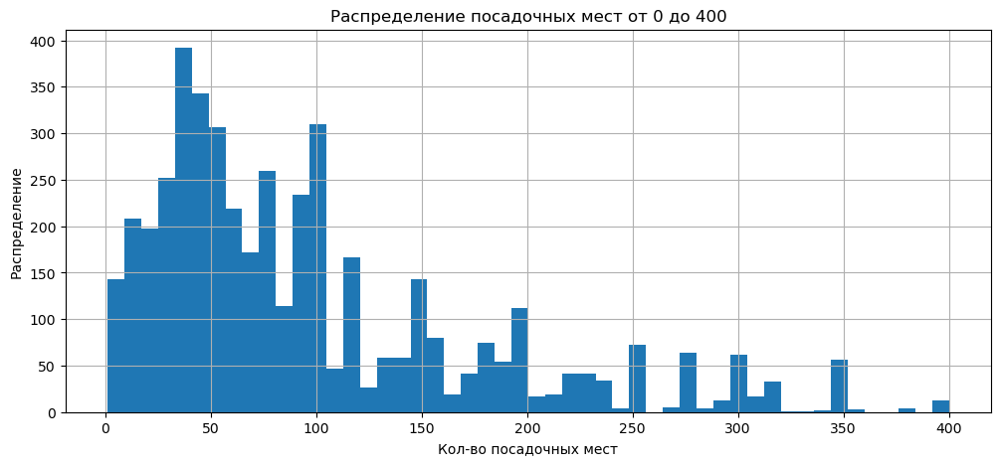

In [20]:
df['seats'].hist(figsize=(12,5), label='Посадочных мест от 0 до 400', bins=50, range=(1,400))

plt.xlabel('Кол-во посадочных мест')
plt.ylabel('Распределение')
plt.title('Распределение посадочных мест от 0 до 400')

plt.show()

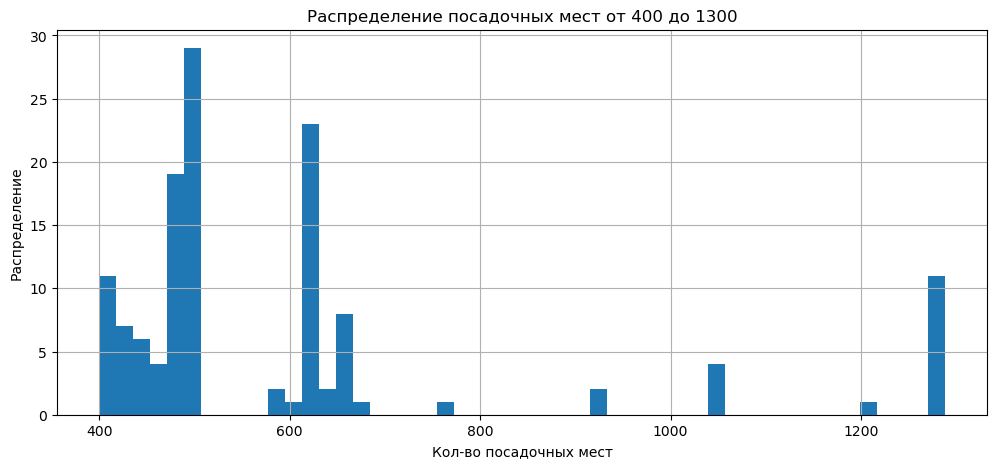

In [21]:
df['seats'].hist(figsize=(12,5), bins=50, range=(400,1288))

plt.xlabel('Кол-во посадочных мест')
plt.ylabel('Распределение')
plt.title('Распределение посадочных мест от 400 до 1300')

plt.show()

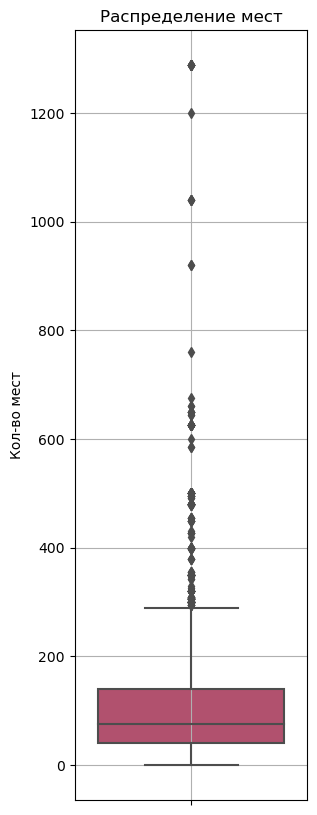

In [22]:
plt.figure(figsize=(3,10))
sns.boxplot(y='seats', data=df, palette='flare')

plt.ylabel('Кол-во мест')
plt.title('Распределение мест')
plt.grid()

In [23]:
df[df['seats'].isna()].head()

,name,category,address,district,hours,lat,lng,rating,price,avg_bill,middle_avg_bill,middle_coffee_cup,chain,seats
0,WoWфли,кафе,"Москва, улица Дыбенко, 7/1",Северный административный округ,"ежедневно, 10:00–22:00",55.878494,37.478860,5.0,NaN,NaN,NaN,NaN,0,NaN
3,Dormouse Coffee Shop,кофейня,"Москва, улица Маршала Федоренко, 12",Северный административный округ,"ежедневно, 09:00–22:00",55.881608,37.488860,5.0,NaN,Цена чашки капучино:155–185 ₽,NaN,170.0,0,NaN
5,Sergio Pizza,пиццерия,"Москва, Ижорская улица, вл8Б",Северный административный округ,"ежедневно, 10:00–23:00",55.888010,37.509573,4.6,средние,NaN,NaN,NaN,0,NaN
11,Шашлык Шефф,кафе,"Москва, улица Маршала Федоренко, 10с1",Северный административный округ,"ежедневно, 10:00–21:00",55.881770,37.492362,4.9,NaN,NaN,NaN,NaN,0,NaN
12,Заправка,кафе,"Москва, МКАД, 80-й километр, 1",Северный административный округ,вт-сб 09:00–18:00,55.899938,37.517958,4.3,средние,Средний счёт:330 ₽,330.0,NaN,0,NaN


Большая часть значений расположена в диапазоне 0 - 200 мест. Присутствуют большие значения до 1288 мест, но это вполне могут быть крупные столовые или банкетные залы. Есть пропуски, но их невозможно заполнить без доп. информации, а удалять их будет некорректно из-за искажения данных. Потому отсавляем как есть

**В результате обработки**, явных дубликатов не выявлено, есть пропуски. К сожалению, обработать большую часть из них невозможно. 

Так, рабочие часы и кол-во мест зависит от помещения и правил компаний. Столбцы `middle_avg_bill` и `middle_coffee_cup` не могут быть заполнены из-за отсутствия статистики.

Также трудно предсказать средний чек и категории цен в заведении. И кажется некорректно ставить медианное значение и тем более 0. Поэтому пропуски стоит оставить, чтобы избежать искажения данных

In [24]:
# создадем столбец с названием улицы
df['street'] = df['address'].str.split(', ').str[1]

In [25]:
# создадим столбец, с обозначением, что заведение работает ежедневно и круглосуточно
df['is_24/7'] = df['hours'].str.contains('ежедневно, круглосуточно')

In [26]:
df.head()

,name,category,address,district,hours,lat,lng,rating,price,avg_bill,middle_avg_bill,middle_coffee_cup,chain,seats,street,is_24/7
0,WoWфли,кафе,"Москва, улица Дыбенко, 7/1",Северный административный округ,"ежедневно, 10:00–22:00",55.878494,37.478860,5.0,NaN,NaN,NaN,NaN,0,NaN,улица Дыбенко,False
1,Четыре комнаты,ресторан,"Москва, улица Дыбенко, 36, корп. 1",Северный административный округ,"ежедневно, 10:00–22:00",55.875801,37.484479,4.5,выше среднего,Средний счёт:1500–1600 ₽,1550.0,NaN,0,4.0,улица Дыбенко,False
2,Хазри,кафе,"Москва, Клязьминская улица, 15",Северный административный округ,"пн-чт 11:00–02:00; пт,сб 11:00–05:00; вс 11:00...",55.889146,37.525901,4.6,средние,Средний счёт:от 1000 ₽,1000.0,NaN,0,45.0,Клязьминская улица,False
3,Dormouse Coffee Shop,кофейня,"Москва, улица Маршала Федоренко, 12",Северный административный округ,"ежедневно, 09:00–22:00",55.881608,37.488860,5.0,NaN,Цена чашки капучино:155–185 ₽,NaN,170.0,0,NaN,улица Маршала Федоренко,False
4,Иль Марко,пиццерия,"Москва, Правобережная улица, 1Б",Северный административный округ,"ежедневно, 10:00–22:00",55.881166,37.449357,5.0,средние,Средний счёт:400–600 ₽,500.0,NaN,1,148.0,Правобережная улица,False


In [27]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8406 entries, 0 to 8405
Data columns (total 16 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   name               8406 non-null   object 
 1   category           8406 non-null   object 
 2   address            8406 non-null   object 
 3   district           8406 non-null   object 
 4   hours              7870 non-null   object 
 5   lat                8406 non-null   float64
 6   lng                8406 non-null   float64
 7   rating             8406 non-null   float64
 8   price              3315 non-null   object 
 9   avg_bill           3816 non-null   object 
 10  middle_avg_bill    3149 non-null   float64
 11  middle_coffee_cup  535 non-null    float64
 12  chain              8406 non-null   int64  
 13  seats              4795 non-null   float64
 14  street             8406 non-null   object 
 15  is_24/7            7870 non-null   object 
dtypes: float64(6), int64(1),

**Вывод**

- Дубликатов не было выялено
- Пропуски присутсвуют, но приянто решение их оставить, чтобы избежать искажения данных
- Добавлены новые столбецы с с названиями улиц и обозначением, что заведение работает ежедневно и круглосуточно (24/7)

## Шаг 3. Анализ данных

### Кол-во объектов общественного питания по категориям

In [28]:
df['category'].unique()

array(['кафе', 'ресторан', 'кофейня', 'пиццерия', 'бар,паб',
       'быстрое питание', 'булочная', 'столовая'], dtype=object)

In [29]:
count_category = (
    df.groupby('category').agg({'name':'count'}).reset_index()
    .rename(columns={'name':'cnt'}).sort_values(by = 'cnt', ascending=False)
)
count_category

,category,cnt
3,кафе,2378
6,ресторан,2043
4,кофейня,1413
0,"бар,паб",765
5,пиццерия,633
2,быстрое питание,603
7,столовая,315
1,булочная,256


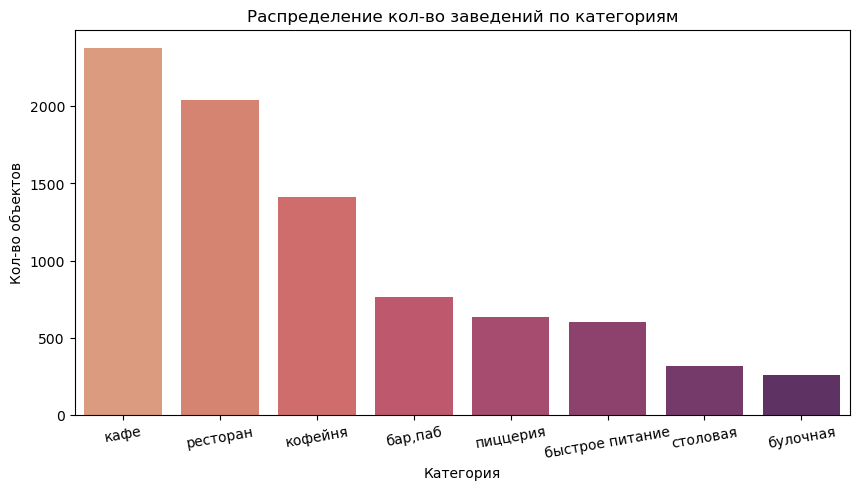

In [31]:
plt.subplots(figsize=(10, 5))
sns.barplot(x='category', y='cnt', data=count_category, palette='flare')

plt.title('Распределение кол-во заведений по категориям')
plt.xticks(rotation=10)
plt.ylabel('Кол-во объектов')
plt.xlabel('Категория')

plt.show()

В Москве больше всего заведений категории кафе, на втором месте рестораны и на третьем - кофейни.

### Кол-во посадочных мест в заведениях по категориям

In [32]:
temp = df.groupby('category').agg({'seats':'count'}).reset_index().sort_values(by='seats', ascending=False)
temp

,category,seats
6,ресторан,1270
3,кафе,1218
4,кофейня,751
0,"бар,паб",468
5,пиццерия,427
2,быстрое питание,349
7,столовая,164
1,булочная,148


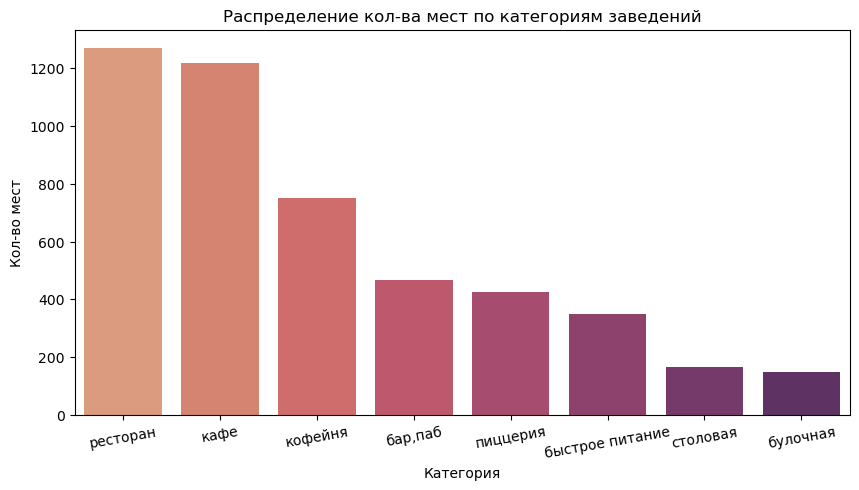

In [33]:
plt.subplots(figsize=(10, 5))
sns.barplot(x='category', y='seats', data=temp, palette='flare')

plt.title('Распределение кол-ва мест по категориям заведений')
plt.xticks(rotation=10)
plt.ylabel('Кол-во мест')
plt.xlabel('Категория')

plt.show()

Самое большое кол-во посадочных мест ожидаемо в ресторанах, на втором месте - кафе и далее кофейни. 

In [34]:
# посмотрим еще среднее и медианное значения
df.pivot_table(index='category', values='seats', aggfunc=['mean', 'median'])

,mean,median
,seats,seats
category,,
"бар,паб",124.532051,82.5
булочная,89.385135,50.0
быстрое питание,98.891117,65.0
кафе,97.512315,60.0
кофейня,111.199734,80.0
пиццерия,94.496487,55.0
ресторан,121.944094,86.0
столовая,99.750000,75.5


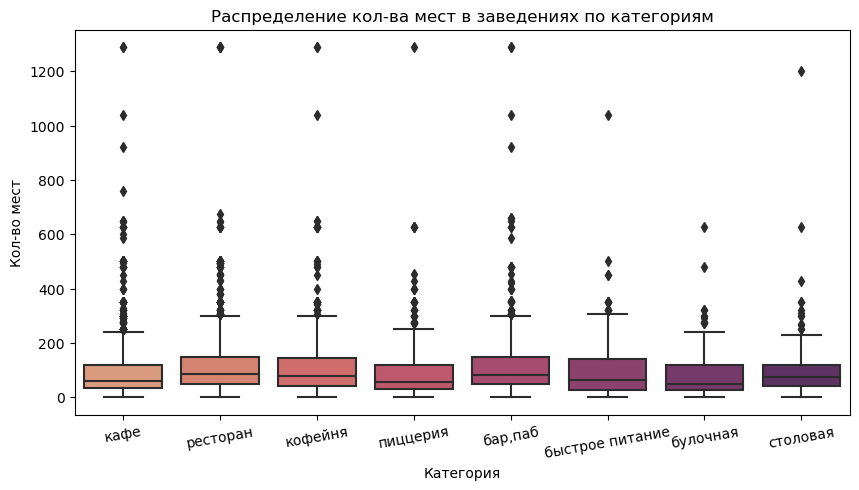

In [35]:
plt.subplots(figsize=(10, 5))
sns.boxplot(x='category', y='seats', data=df, palette='flare')

plt.title('Распределение кол-ва мест в заведениях по категориям')
plt.ylabel('Кол-во мест')
plt.xlabel('Категория')
plt.xticks(rotation=10)

plt.show()

Cреднее и медианные значения достаточно сильно отличаются. Скорее всего это связано c большой разницей в кол-ве мест внутри одной категории, что дает выбросы в данных

### Соотношение сетевых и несетевых заведений

In [36]:
df['chain'].value_counts()

0    5201
1    3205
Name: chain, dtype: int64

In [37]:
fig = go.Figure(data=go.Pie(values=df['chain'].value_counts(),
               labels=['несетевые', 'сетевые']))

fig.layout.title='Соотношение сетевых и несетевых заведений по количеству'
fig.show()

Сетевых заведений 38,1% от общего числа заведений и соответственно 61,9% заведений являются несетевыми в Москве 

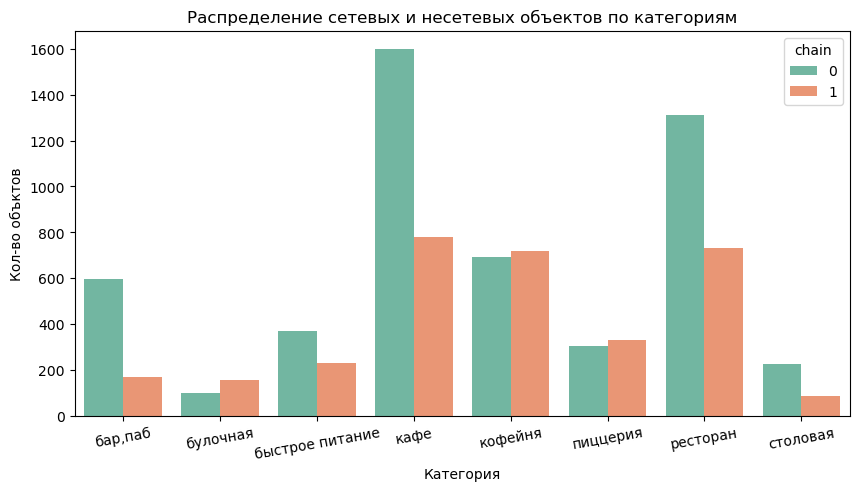

In [38]:
chain = df.groupby(['category', 'chain'])['chain'].count()
chain.name = 'cnt'
chain = chain.reset_index()

plt.subplots(figsize=(10, 5))
sns.barplot(data=chain, x="category", y="cnt", hue="chain", palette='Set2')

plt.title('Распределение сетевых и несетевых объектов по категориям')
plt.ylabel('Кол-во объктов')
plt.xlabel('Категория')
plt.xticks(rotation=10)

plt.show()

In [40]:
chain_sum = chain.groupby('category')['cnt'].sum().reset_index()
chain_sum.columns = ['category','sum']
chain_yes = chain_places.merge(chain_sum, on='category', how='left')
chain_yes['part'] = (chain_yes['cnt'] / chain_yes['sum']).round(3)
chain_yes = chain_yes.sort_values(by='part', ascending=False)
chain_yes

,category,chain,cnt,sum,part
6,булочная,1,157,256,0.613
3,пиццерия,1,330,633,0.521
2,кофейня,1,720,1413,0.510
4,быстрое питание,1,232,603,0.385
1,ресторан,1,730,2043,0.357
0,кафе,1,779,2378,0.328
7,столовая,1,88,315,0.279
5,"бар,паб",1,169,765,0.221


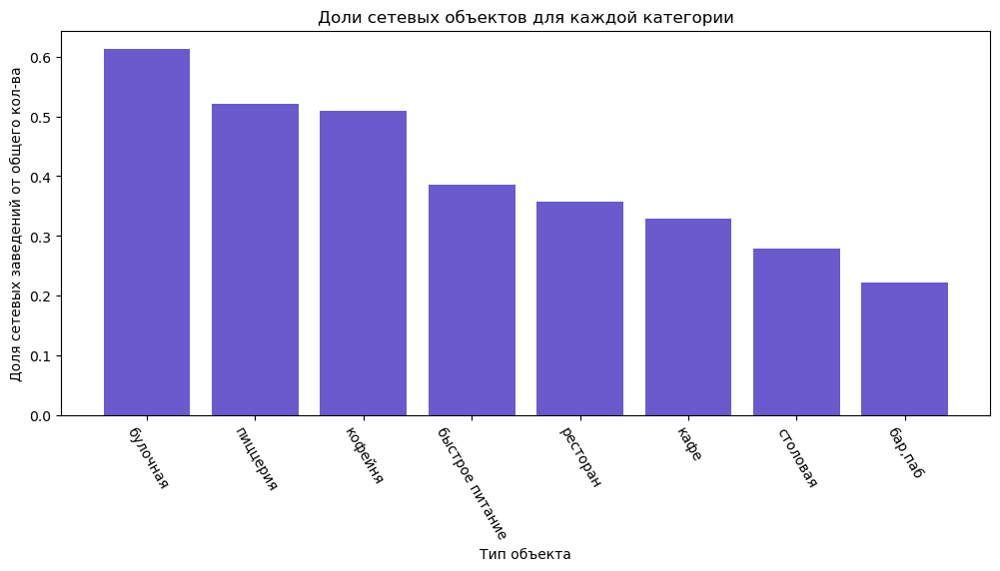

In [41]:
plt.figure(figsize=(12,5))
plt.bar(x=chain_yes['category'], height=chain_yes['part'], color='slateblue')
plt.title('Доли сетевых объектов для каждой категории')
plt.ylabel('Доля сетевых заведений от общего кол-ва')
plt.xlabel('Тип объекта')
plt.xticks(rotation=300)

plt.show()

Чаще всего сетевыми заведениями являются булочные, пиццерии и кофейни

### Tоп-15 популярных сетей в Москве

In [42]:
chain_df = df[df['chain'] == 1]
temp = pd.DataFrame(chain_df.groupby('name')['category'].count().sort_values(ascending=False).head(15)).reset_index()
temp = temp.rename(columns={'category':'cnt'})
temp

,name,cnt
0,Шоколадница,120
1,Домино'с Пицца,76
2,Додо Пицца,74
3,One Price Coffee,71
4,Яндекс Лавка,69
5,Cofix,65
6,Prime,50
7,Хинкальная,44
8,КОФЕПОРТ,42
9,Кулинарная лавка братьев Караваевых,39


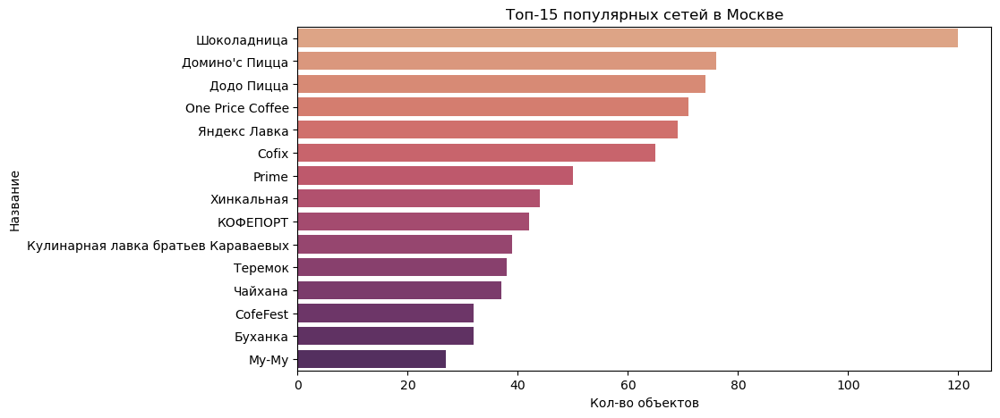

In [43]:
plt.subplots(figsize=(10, 5))
sns.barplot(x='cnt', y='name', data=temp, palette='flare')

plt.title('Tоп-15 популярных сетей в Москве')
plt.ylabel('Название')
plt.xlabel('Кол-во объектов')

plt.show()

Cамыми популярными в Москве являются Шоколадница, Домино'с пицца и Додо Пицца. Посмотрим на категории этих заведений

In [44]:
temp1 = pd.DataFrame(
    chain_df.groupby(['name', 'category'], as_index=False).agg({'district':'count'})
    .rename(columns={'district':'cnt'}).sort_values(by = 'cnt', ascending=False).head(15)
)

temp1.reset_index()

,index,name,category,cnt
0,1142,Шоколадница,кофейня,119
1,504,Домино'с Пицца,пиццерия,76
2,497,Додо Пицца,пиццерия,74
3,206,One Price Coffee,кофейня,71
4,1158,Яндекс Лавка,ресторан,69
5,73,Cofix,кофейня,65
6,242,Prime,ресторан,49
7,558,КОФЕПОРТ,кофейня,42
8,644,Кулинарная лавка братьев Караваевых,кафе,39
9,978,Теремок,ресторан,36


Ранее выснили, что больше всего ресторанов, кафе и кофеен, но также есть 2 большие сети пиццерий по городу

### Распределение заведений по районам Москвы 

In [45]:
df['district'].unique()

array(['Северный административный округ',
       'Северо-Восточный административный округ',
       'Северо-Западный административный округ',
       'Западный административный округ',
       'Центральный административный округ',
       'Восточный административный округ',
       'Юго-Восточный административный округ',
       'Южный административный округ',
       'Юго-Западный административный округ'], dtype=object)

В датасете представлено 9 районов Москвы 

In [46]:
data = df.pivot_table(index='district', columns='category', values='address', aggfunc='count')
data

category,"бар,паб",булочная,быстрое питание,кафе,кофейня,пиццерия,ресторан,столовая
district,,,,,,,,
Восточный административный округ,53,25,71,272,105,72,160,40
Западный административный округ,50,37,62,239,150,71,218,24
Северный административный округ,68,39,58,235,193,77,189,41
Северо-Восточный административный округ,63,28,82,269,159,68,182,40
Северо-Западный административный округ,23,12,30,115,62,40,109,18
Центральный административный округ,364,50,87,464,428,113,670,66
Юго-Восточный административный округ,38,13,67,282,89,55,145,25
Юго-Западный административный округ,38,27,61,238,96,64,168,17
Южный административный округ,68,25,85,264,131,73,202,44


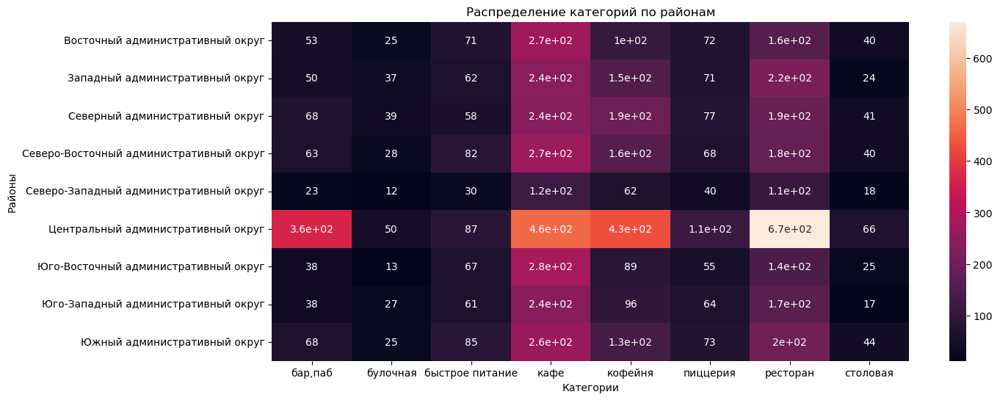

In [47]:
plt.figure(figsize=(14,6))
sns.heatmap(data, annot=True)

plt.title('Распределение категорий по районам')
plt.ylabel('Районы')
plt.xlabel('Категории')

plt.show()

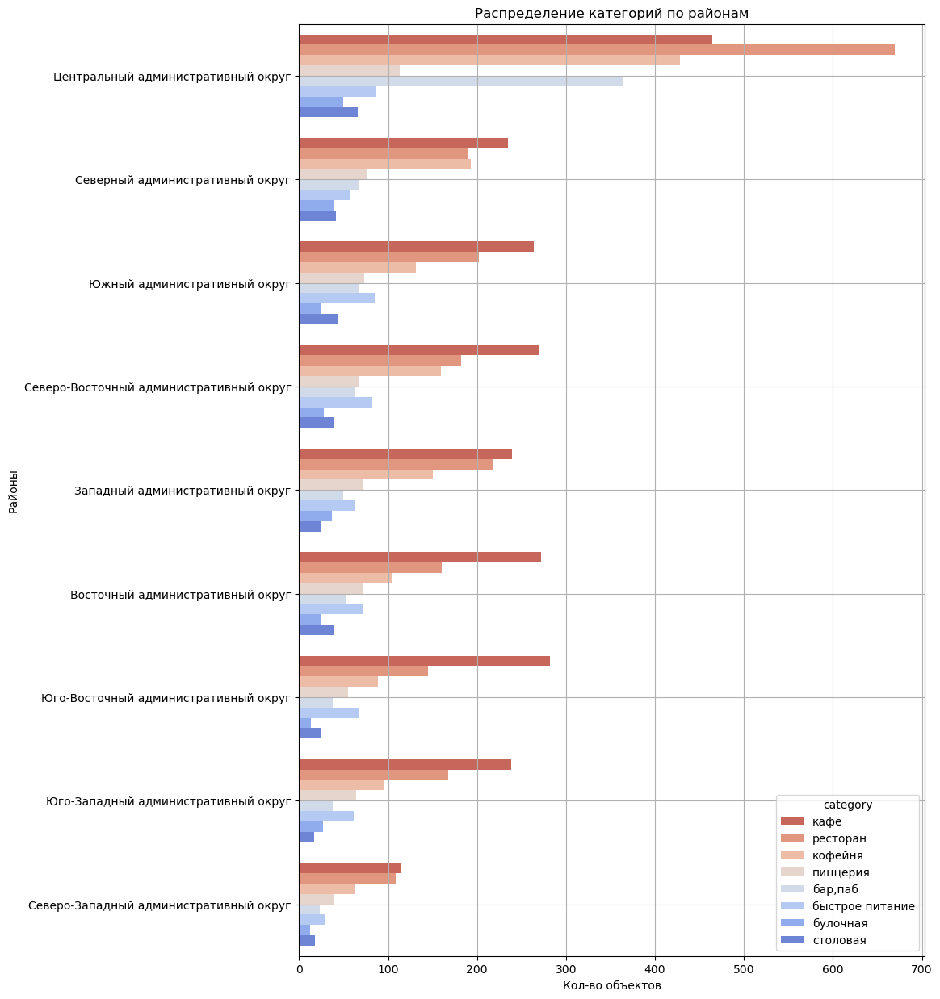

In [48]:
plt.figure(figsize=(10, 15))
sns.countplot(y='district', hue='category', data=df, palette='coolwarm_r', 
             order = df['district'].value_counts().index)

plt.title('Распределение категорий по районам')
plt.ylabel('Районы')
plt.xlabel('Кол-во объектов')
plt.grid()

plt.show()

Выделяется центральный округ. Ожидаемо, там больше всего заведений, а именно ресторанов. Кафе во всех регионах лежат в дианопозе от 200 до 500. Можно отметить, что больше всего баров\пабов расположено именно в центральном районе, как собственно и кофейн. 

### Распределение средних рейтингов по категориям заведений

In [49]:
data = df.groupby('category')['rating'].mean().sort_values(ascending=False)
data

category
бар,паб            4.387712
пиццерия           4.301264
ресторан           4.290357
кофейня            4.277282
булочная           4.268359
столовая           4.211429
кафе               4.123886
быстрое питание    4.050249
Name: rating, dtype: float64

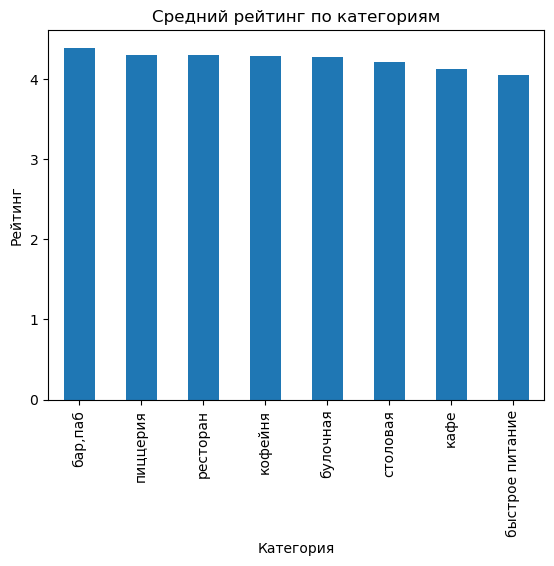

In [50]:
data.plot(kind='bar', legend=None)

plt.title('Средний рейтинг по категориям')
plt.xlabel('Категория')
plt.ylabel('Рейтинг')

plt.show()

Все средние рейтинги выше 4 баллов, но они самые низкие у быстрого питания. В среднем, самые высокие рейтинги у баров и пабов.

### Хороплет со средним рейтингом заведений каждого района

In [51]:
rating_df = df.groupby('district', as_index=False)['rating'].agg('mean')

# загружаем JSON-файл с границами округов Москвы
state_geo = 'https://code.s3.yandex.net/data-analyst/admin_level_geomap.geojson' 
# moscow_lat - широта центра Москвы, moscow_lng - долгота центра Москвы
moscow_lat, moscow_lng = 55.751244, 37.618423

# создаём карту Москвы
m = Map(location=[moscow_lat, moscow_lng], zoom_start=10)

# создаём хороплет с помощью конструктора Choropleth и добавляем его на карту
Choropleth(
    geo_data=state_geo,
    data=rating_df,
    columns=['district', 'rating'],
    key_on='feature.name',
    fill_color='YlGn',
    fill_opacity=0.8,
    legend_name='Средний рейтинг заведений по районам',
).add_to(m)

# выводим карту
m

Самые хорошие средние рейтинги заведений в Центральном районе.

Далее отобразим все заведения датасета на карте с помощью кластеров

In [52]:
# moscow_lat - широта центра Москвы, moscow_lng - долгота центра Москвы
moscow_lat, moscow_lng = 55.751244, 37.618423

# создаём карту Москвы
m = Map(location=[moscow_lat, moscow_lng], zoom_start=10)
# создаём пустой кластер, добавляем его на карту
marker_cluster = MarkerCluster().add_to(m)

# пишем функцию, которая принимает строку датафрейма,
# создаёт маркер в текущей точке и добавляет его в кластер marker_cluster
def create_clusters(row):
    Marker(
        [row['lat'], row['lng']],
        popup=f"{row['name']} {row['rating']}",
    ).add_to(marker_cluster)

# применяем функцию create_clusters() к каждой строке датафрейма
df.apply(create_clusters, axis=1)

# выводим карту
m

<div class="alert alert-success" style="border-radius: 10px; box-shadow: 2px 2px 2px; border: 1px solid; padding: 10px ">
<b>Комментарий ревьюера v.1</b> 
    
👍 
Отлично. Здесь все корректно.
</div>

### Топ-15 улиц по количеству заведений

In [53]:
temp = df.pivot_table(index='street', values='name', aggfunc='count').sort_values(by='name', ascending=False).head(15)
top_st = temp.index
temp

,name
street,
проспект Мира,184
Профсоюзная улица,122
проспект Вернадского,108
Ленинский проспект,107
Ленинградский проспект,95
Дмитровское шоссе,88
Каширское шоссе,77
Варшавское шоссе,76
Ленинградское шоссе,70


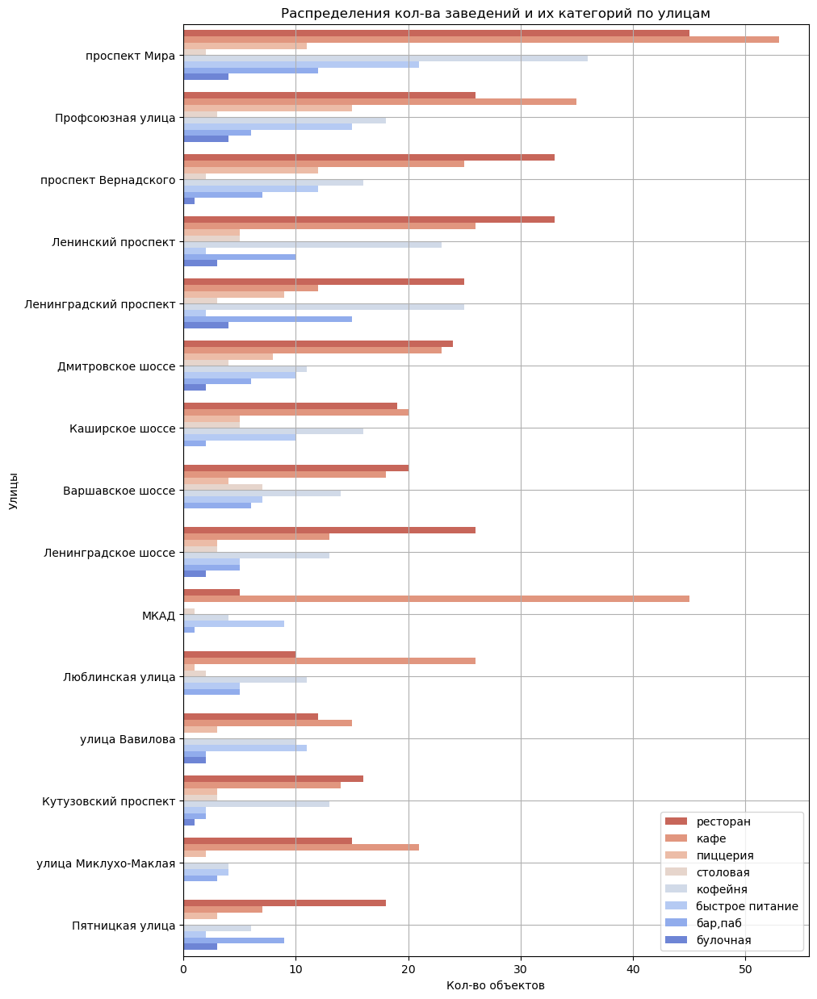

In [54]:
temp = df.query('street in @top_st')

plt.figure(figsize=(10, 15))
sns.countplot(y='street', hue='category', data=temp, palette='coolwarm_r',
             order = temp['street'].value_counts().index)

plt.title('Распределения кол-ва заведений и их категорий по улицам')
plt.ylabel('Улицы')
plt.xlabel('Кол-во объектов')
plt.legend(loc='lower right')
plt.grid()

plt.show()

Больше всего ресторанов на улицах: проспект Мира, Ленинский проект, проспект Вернадского. Больше всего кафе: МКАД, проспект Мира, Профсоюзная улица и Люблинская улица. Больше всего кофейн на проспекте Мира.

Посмотрим улицы, на которых находится только один объект общепита

In [55]:
temp = df.pivot_table(index='street', values='name', aggfunc='count').sort_values(by='name')
temp.columns = ['count']
temp = temp[temp['count'] == 1]
print('Кол-во улиц c одиним объектом общепита:', temp.shape[0])

Кол-во улиц c одиним объектом общепита: 458


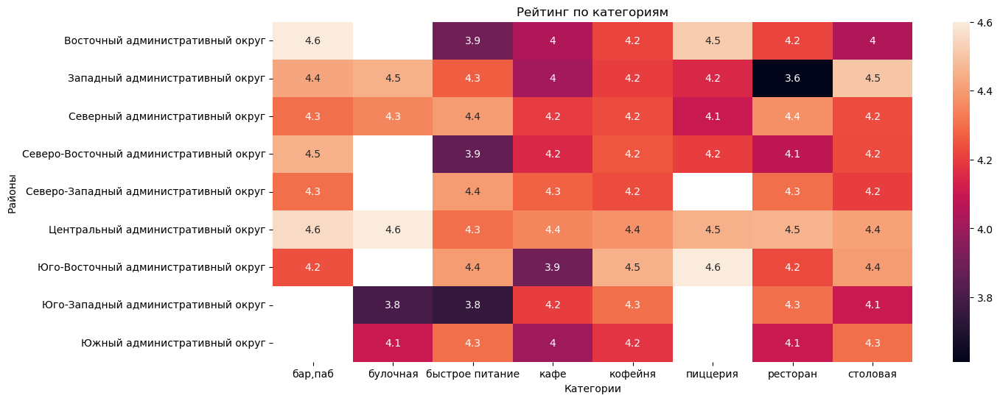

In [56]:
# посмотрим в каких районах они раположены и какой у этих объектов у них рейтинг
temp1 = temp.index
temp1 = df.query('street in @temp1')

data = temp1.pivot_table(index='district', columns='category', values='rating', aggfunc='mean')
plt.figure(figsize=(14,6))
sns.heatmap(data, annot=True)

plt.title('Рейтинг по категориям')
plt.ylabel('Районы')
plt.xlabel('Категории')

plt.show()

Рейтинги в некоторых районах отсутствуют. Но в остальном они достаточно высокие. Скорее всего это связано с тем, что у посетителей нет альтернатив

### Хороплет со средним чеком заведений каждого района

In [57]:
avg_bill = df.groupby('district', as_index=False)['middle_avg_bill'].agg('median')

# загружаем JSON-файл с границами округов Москвы
state_geo = 'https://code.s3.yandex.net/data-analyst/admin_level_geomap.geojson' 
# moscow_lat - широта центра Москвы, moscow_lng - долгота центра Москвы
moscow_lat, moscow_lng = 55.751244, 37.618423

# создаём карту Москвы
m = Map(location=[moscow_lat, moscow_lng], zoom_start=10)

# создаём хороплет с помощью конструктора Choropleth и добавляем его на карту
Choropleth(
    geo_data=state_geo,
    data=avg_bill,
    columns=['district', 'middle_avg_bill'],
    key_on='feature.name',
    fill_color='YlGn',
    fill_opacity=0.8,
    legend_name='Медианный чек заведений по районам',
).add_to(m)

# выводим карту
m

Предсказуемо, самый высокий средний чек у заведений, расположенных в Центральном и Западном районах. Самый низкий же в более "бюджетных" районах - Северо-восточный, Юго-восточном и Южном районах

**Вывод**

1. В Москве больше всего кафе, меньше ресторанов и кофейн
2. Больше всего посадочных мест нужно для ресторанов или баров. Меньше всего для булочных
3. Большая часть заведений – несетевые
4. Сетевыми заведениями чаще всего являются булочные, пиццерии и кофейни
5. Cамыми популярными в Москве являются Шоколадница, Домино'с пицца, Додо Пицца и One Price Coffee
6. Больше всего заведений в Центральном округе, в основом там расположены рестораны и бары\пабы с хорошим рейтингом
7. Самые высокие рейтинги у баров и пабов, самые низкие у быстрого питания
9. Самой большой по количеству заведений является улица проект Мира. На 458 улицах находится только 1 заведение
10. Самый высокий средний чек у заведений, расположенных в Центральном и Западном районах

## Шаг 4. Детализация исследования: открытие кофейни

Основателям фонда «Shut Up and Take My Money» не даёт покоя успех сериала «Друзья». Их мечта — открыть такую же крутую и доступную, как «Central Perk», кофейню в Москве. Будем считать, что заказчики не боятся конкуренции в этой сфере, ведь кофеен в больших городах уже достаточно.

В данном разделе будут даны ответы на следующие вопросы:

- Сколько всего кофеен в датасете? В каких районах их больше всего, каковы особенности их расположения?
- Есть ли круглосуточные кофейни?
- Какие у кофеен рейтинги? Как они распределяются по районам?
- На какую стоимость чашки капучино стоит ориентироваться при открытии и почему?

In [58]:
temp = df[df['category'] == 'кофейня']
print('Кол-во кофеен в датасете:', temp.shape[0])

Кол-во кофеен в датасете: 1413


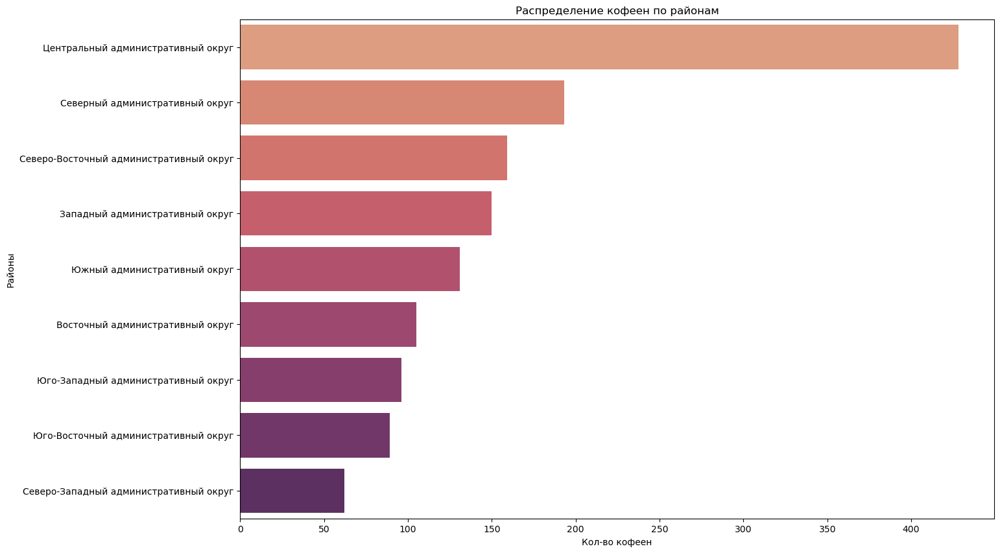

In [59]:
# распределение по районам
plt.figure(figsize=(15, 10))
sns.countplot(y='district', data=temp, palette='flare', 
             order = temp['district'].value_counts().index)

plt.title('Распределение кофеен по районам')
plt.ylabel('Районы')
plt.xlabel('Кол-во кофеен')

plt.show()

In [60]:
# посмотрим их распределение по районам
temp_cnt = temp.groupby('district', as_index=False)['name'].agg('count')

# загружаем JSON-файл с границами округов Москвы
state_geo = 'https://code.s3.yandex.net/data-analyst/admin_level_geomap.geojson' 
# moscow_lat - широта центра Москвы, moscow_lng - долгота центра Москвы
moscow_lat, moscow_lng = 55.751244, 37.618423

# создаём карту Москвы
m = Map(location=[moscow_lat, moscow_lng], zoom_start=10)

# создаём хороплет с помощью конструктора Choropleth и добавляем его на карту
Choropleth(
    geo_data=state_geo,
    data=temp_cnt,
    columns=['district', 'name'],
    key_on='feature.name',
    fill_color='YlGn',
    fill_opacity=0.8,
    legend_name='Количество кофеен по районам',
).add_to(m)

# выводим карту
m

Больше всего кофеен в центральном округе. В остальных округах их кол-тво от 50 до 200 заведений на район

In [61]:
print('Кол-во круглосуточных кофеен:', temp['is_24/7'].sum())

Кол-во круглосуточных кофеен: 59


In [62]:
# посмотрим их распределение по районам
temp_24_7 = temp.groupby('district', as_index=False)['is_24/7'].agg('sum')

# загружаем JSON-файл с границами округов Москвы
state_geo = 'https://code.s3.yandex.net/data-analyst/admin_level_geomap.geojson' 
# moscow_lat - широта центра Москвы, moscow_lng - долгота центра Москвы
moscow_lat, moscow_lng = 55.751244, 37.618423

# создаём карту Москвы
m = Map(location=[moscow_lat, moscow_lng], zoom_start=10)

# создаём хороплет с помощью конструктора Choropleth и добавляем его на карту
Choropleth(
    geo_data=state_geo,
    data=temp_24_7,
    columns=['district', 'is_24/7'],
    key_on='feature.name',
    fill_color='YlGn',
    fill_opacity=0.8,
    legend_name='Количество круглосуточных кофеен',
).add_to(m)

# выводим карту
m

Больше всего круглосуточных кофеен в центре. В остальных районах их почти нет, выделяются с чуть большим кол-вом районы с большими ценами: западный и юго-западный

In [63]:
print('Медианный рейтинг кофеен:',temp['rating'].median(), "\n" 
      'Средний рейтинг кофеен:',round(temp['rating'].mean(), 2))

Медианный рейтинг кофеен: 4.3 
Средний рейтинг кофеен: 4.28


In [64]:
# посмотрим их распределение по районам
rating = temp.groupby('district', as_index=False)['rating'].agg('median')

# загружаем JSON-файл с границами округов Москвы
state_geo = 'https://code.s3.yandex.net/data-analyst/admin_level_geomap.geojson' 
# moscow_lat - широта центра Москвы, moscow_lng - долгота центра Москвы
moscow_lat, moscow_lng = 55.751244, 37.618423

# создаём карту Москвы
m = Map(location=[moscow_lat, moscow_lng], zoom_start=10)

# создаём хороплет с помощью конструктора Choropleth и добавляем его на карту
Choropleth(
    geo_data=state_geo,
    data=rating,
    columns=['district', 'rating'],
    key_on='feature.name',
    fill_color='YlGn',
    fill_opacity=0.8,
    legend_name='Медианный рейтинг заведений по районам',
).add_to(m)

# выводим карту
m

В западном районе самые низкие рейтинги

In [65]:
print('Ориентироваться на стоимость чашки капучино',
    'от', int(temp['middle_coffee_cup'].median()), 
    'до', round(temp['middle_coffee_cup'].mean()), 'рублей')

Ориентироваться на стоимость чашки капучино от 170 до 175 рублей


In [66]:
# посмотрим их распределение по районам
cost_cap = temp.groupby('district', as_index=False)['middle_coffee_cup'].agg('median')

# загружаем JSON-файл с границами округов Москвы
state_geo = 'https://code.s3.yandex.net/data-analyst/admin_level_geomap.geojson' 
# moscow_lat - широта центра Москвы, moscow_lng - долгота центра Москвы
moscow_lat, moscow_lng = 55.751244, 37.618423

# создаём карту Москвы
m = Map(location=[moscow_lat, moscow_lng], zoom_start=10)

# создаём хороплет с помощью конструктора Choropleth и добавляем его на карту
Choropleth(
    geo_data=state_geo,
    data=cost_cap,
    columns=['district', 'middle_coffee_cup'],
    key_on='feature.name',
    fill_color='YlGn',
    fill_opacity=0.8,
    legend_name='Медианная цена чашки капучино',
).add_to(m)

# выводим карту
m

Самая высокая цена чашки капучино в центральном, западном и юго-западном районах - 'престижные' районы. В среднем цена за чашку 180-190 рублей. Самая низкая цена 135-145 рублей в Восточном районе

**Рекомендация для открытия нового заведения**

- Самое большое кол-во кофеен в центре, а меньше всего на северо-востоке. Так как заказчики не боятся конкуренции в этой сфере, то идеальным местом для открытия кофейни будет центр - большой спрос и проходимость. 
- Круглосуточных кофеен очень мало во всех районах, кроме центрального. Поэтому нет смысла открывать круглосуточное заведение на окраине - спрос небольшой. В центре открыть можно, но стоит учитывать, что скорее всего большим спросом ночью пользуются бары или рестораны, и мало кто предпочтёт пить кофе в это время. 
- Самые низкие по рейтингам кофейни находятся в западном районе. Возможно стоит избегать этот район, так как общая ситуация на рынке не благоприятная и одна кофейня вряд ли изменит картину, а низкие рейтинги могут привести к тому, что кофейня потеряет посетителей и разорится.
- Стоимость чашки капучино должна быть в среднем от 170 до 175 рублей. Такая цена позволит сохранять конкурентоспособность.

## Шаг 5. Презентация

Презентация: https://drive.google.com/drive/folders/1eh8xwPDr9BqnYUEmBbQJSaHP0Pac7ia7